<a href="https://colab.research.google.com/github/ayeshaalamexe/loan-approval-prediction/blob/main/loan_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving loan_data.csv to loan_data (1).csv
Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Missing values:
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

Approved vs Rejected:
Loan_Status
Y    0.687
N    0.313
Name: count, dtype: float64


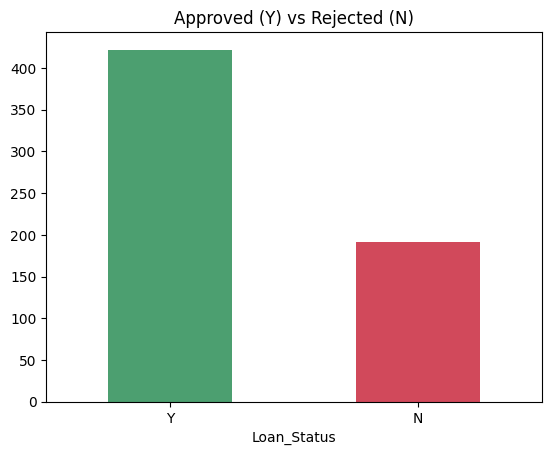

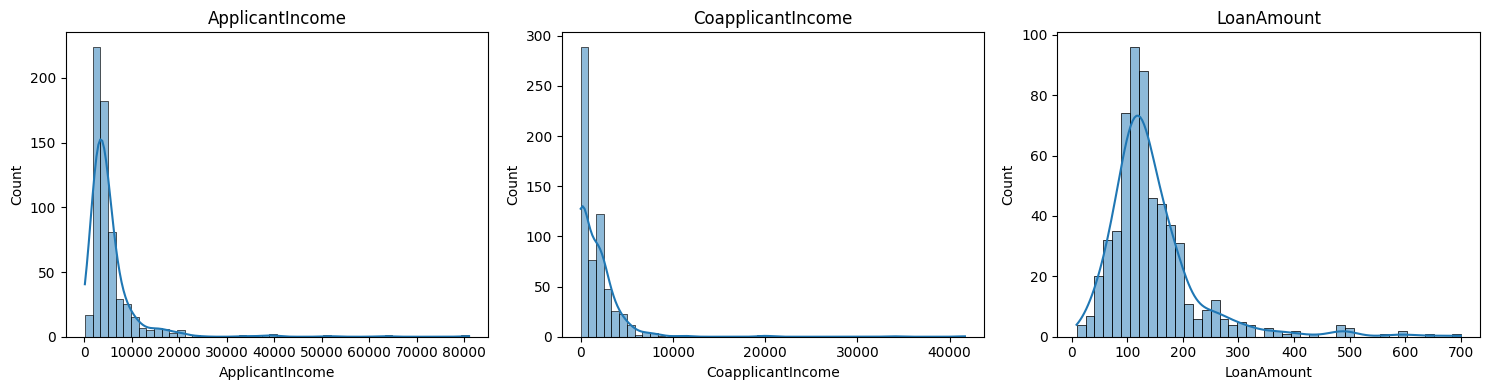

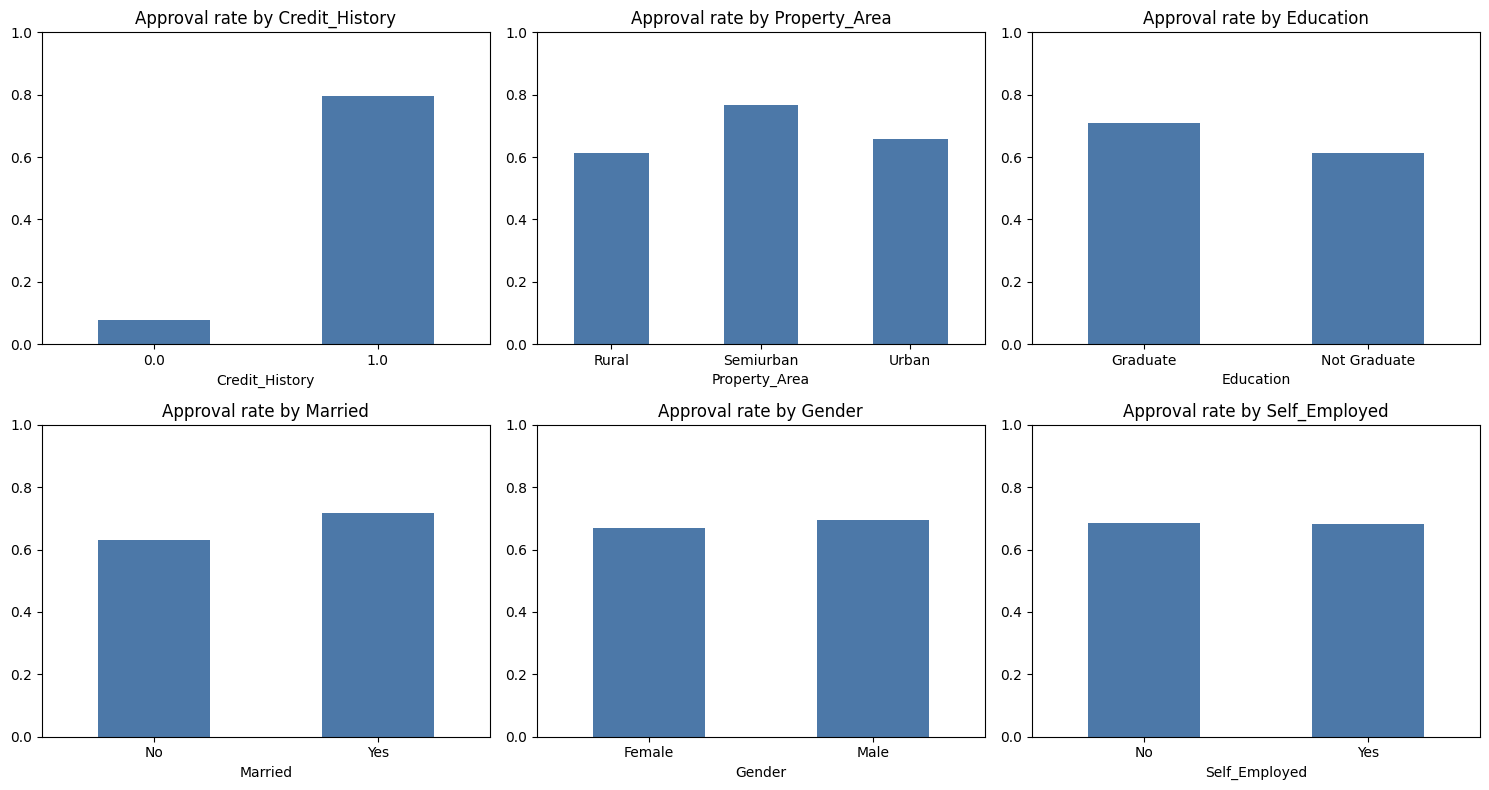

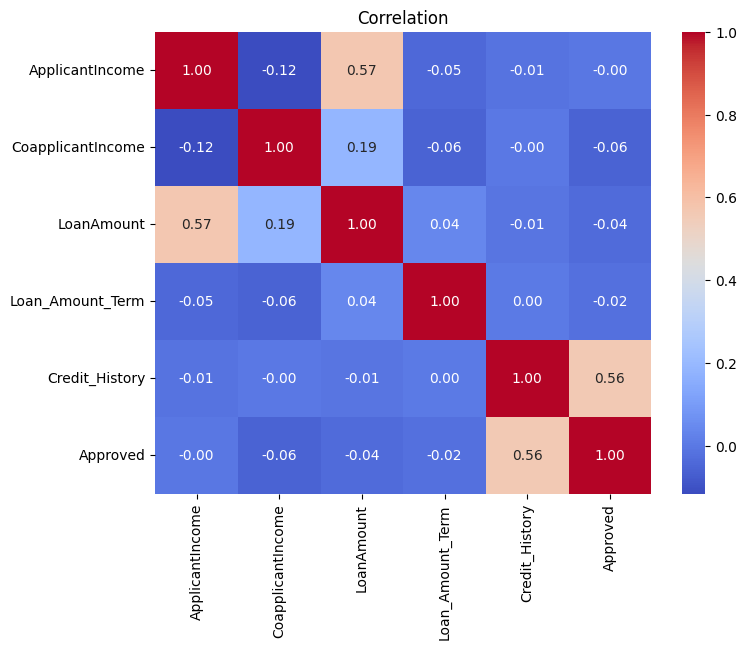

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from google.colab import files
files.upload()

df = pd.read_csv("loan_data.csv")
print("Shape:", df.shape)
display(df.head())

print("\nMissing values:")
miss = df.isnull().sum()
print(miss[miss > 0])

counts = df["Loan_Status"].value_counts()
print("\nApproved vs Rejected:")
print((counts / len(df)).round(3))
counts.plot(kind="bar", color=["#4C9F70", "#D1495B"])
plt.title("Approved (Y) vs Rejected (N)"); plt.xticks(rotation=0); plt.show()

cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, cols):
    sns.histplot(df[c].dropna(), kde=True, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

cat_cols = ["Credit_History", "Property_Area", "Education", "Married", "Gender", "Self_Employed"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cat_cols):
    rate = df.groupby(c)["Loan_Status"].apply(lambda s: (s == "Y").mean())
    rate.plot(kind="bar", ax=ax, color="#4C78A8")
    ax.set_title(f"Approval rate by {c}"); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

tmp = df.copy(); tmp["Approved"] = (tmp["Loan_Status"] == "Y").astype(int)
plt.figure(figsize=(8, 6))
sns.heatmap(tmp.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation"); plt.show()

In [ ]:
d = df.copy()
d = d.drop(columns=["Loan_ID"]).drop_duplicates()

for c in ["Gender", "Married", "Dependents", "Self_Employed", "Credit_History", "Loan_Amount_Term"]:
    d[c] = d[c].fillna(d[c].mode()[0])

d["LoanAmount"] = d["LoanAmount"].fillna(d["LoanAmount"].median())

d["Dependents"] = d["Dependents"].astype(str).replace("3+", "3").astype(int)
d["Loan_Status"] = d["Loan_Status"].map({"Y": 1, "N": 0})

print("Missing values left:", d.isnull().sum().sum())
print("Shape:", d.shape)

Missing values left: 0
Shape: (614, 12)


Skew before: {'TotalIncome': 5.63, 'LoanAmount': 2.74}
Skew after: {'LogTotalIncome': 1.08, 'LogLoanAmount': -0.15}


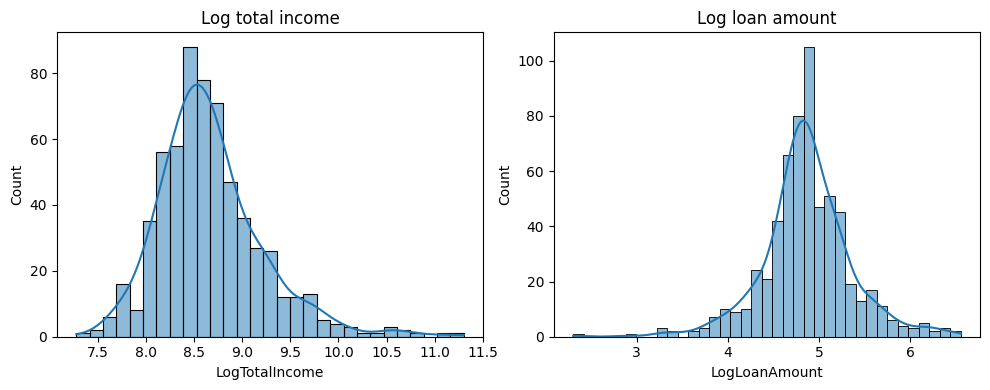

In [ ]:
d["TotalIncome"] = d["ApplicantIncome"] + d["CoapplicantIncome"]
d["LogTotalIncome"] = np.log1p(d["TotalIncome"])
d["LogLoanAmount"] = np.log1p(d["LoanAmount"])
d["LoanToIncome"] = d["LoanAmount"] / d["TotalIncome"]
d["EMI"] = d["LoanAmount"] / d["Loan_Amount_Term"]

print("Skew before:", d[["TotalIncome", "LoanAmount"]].skew().round(2).to_dict())
print("Skew after:", d[["LogTotalIncome", "LogLoanAmount"]].skew().round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(d["LogTotalIncome"], kde=True, ax=axes[0]); axes[0].set_title("Log total income")
sns.histplot(d["LogLoanAmount"], kde=True, ax=axes[1]); axes[1].set_title("Log loan amount")
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

sensitive = d[["Gender", "Married", "Property_Area"]].copy()

X = pd.get_dummies(
    d.drop(columns=["Loan_Status", "ApplicantIncome", "CoapplicantIncome", "LoanAmount", "TotalIncome"]),
    drop_first=True).astype(float)
y = d["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Approved ratio - train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train: (491, 13)  Test: (123, 13)
Approved ratio - train: 0.686  test: 0.691


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "LogReg (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Tree (balanced)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "RF": RandomForestClassifier(n_estimators=200, random_state=42),
    "RF (balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
}

rows = []
for name, m in models.items():
    scaled = name.startswith("LogReg")
    Xtr, Xte = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    rep = classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({
        "Model": name,
        "Precision": rep["1"]["precision"],
        "Recall": rep["1"]["recall"],
        "F1": rep["1"]["f1-score"],
        "Recall (rejected)": rep["0"]["recall"],
        "Accuracy": rep["accuracy"],
        "AUC": roc_auc_score(y_test, m.predict_proba(Xte)[:, 1]),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Precision,Recall,F1,Recall (rejected),Accuracy,AUC
Model,,,,,,
LogReg,0.832,0.988,0.903,0.553,0.854,0.878
LogReg (balanced),0.915,0.882,0.898,0.816,0.862,0.884
Tree,0.851,0.941,0.894,0.632,0.846,0.838
Tree (balanced),0.854,0.965,0.906,0.632,0.862,0.805
RF,0.876,0.918,0.897,0.711,0.854,0.854
RF (balanced),0.876,0.918,0.897,0.711,0.854,0.853


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "RF": RandomForestClassifier(n_estimators=200, random_state=42),
}
cv_rows = []
for name, m in cv_models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="f1")
    cv_rows.append({"Model": name, "F1 mean": scores.mean(), "F1 std": scores.std()})
pd.DataFrame(cv_rows).set_index("Model").round(3)

,F1 mean,F1 std
Model,,
LogReg,0.875,0.009
Tree,0.869,0.010
RF,0.861,0.013


Best model by F1: Tree (balanced)


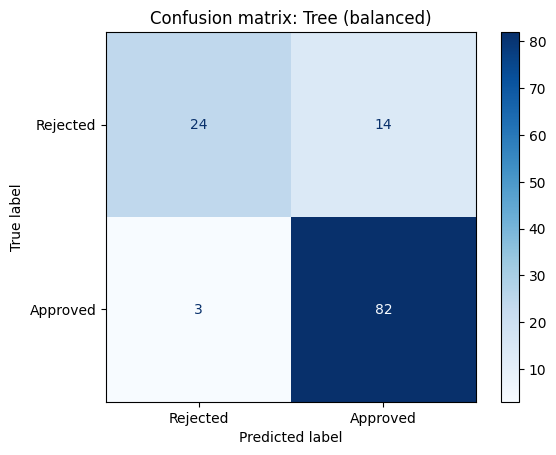

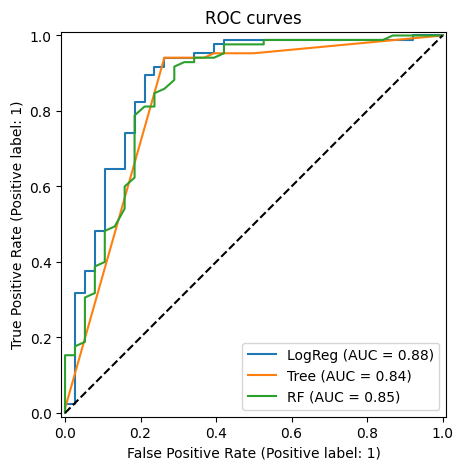

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

best = results["F1"].idxmax()
print("Best model by F1:", best)
m = models[best]
Xe = X_test_s if best.startswith("LogReg") else X_test
ConfusionMatrixDisplay.from_estimator(m, Xe, y_test, display_labels=["Rejected", "Approved"], cmap="Blues")
plt.title(f"Confusion matrix: {best}"); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name in ["LogReg", "Tree", "RF"]:
    mm = models[name]
    Xe = X_test_s if name.startswith("LogReg") else X_test
    RocCurveDisplay.from_estimator(mm, Xe, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
plt.title("ROC curves"); plt.show()

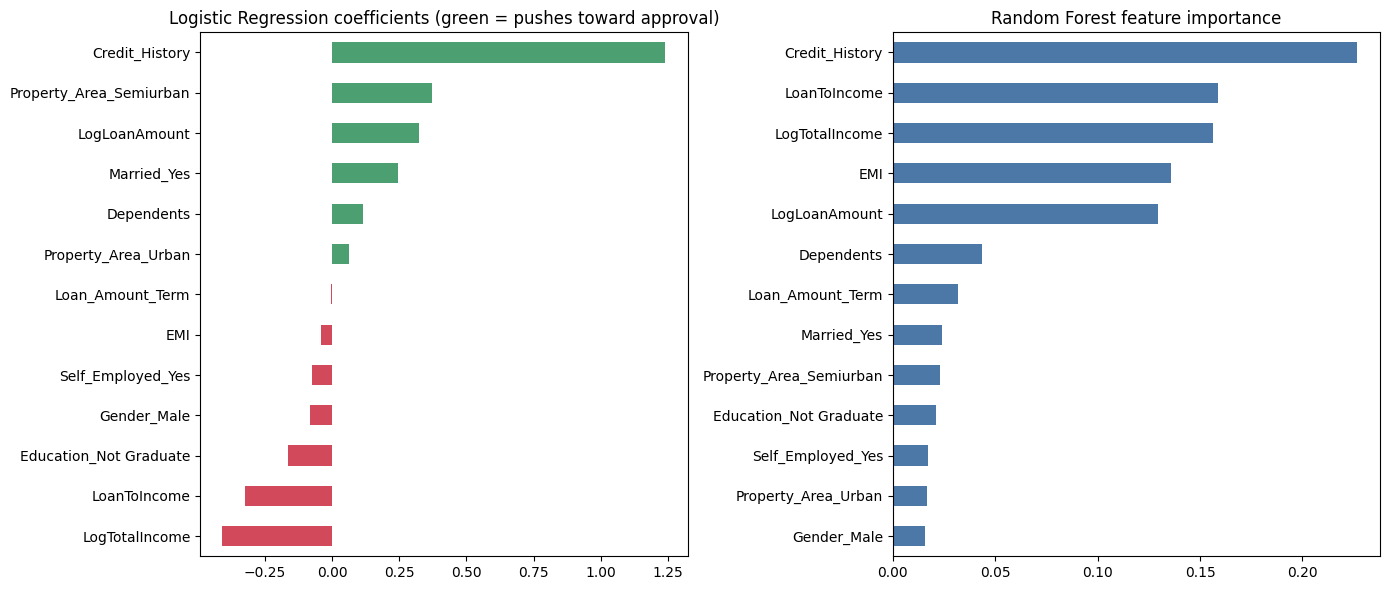

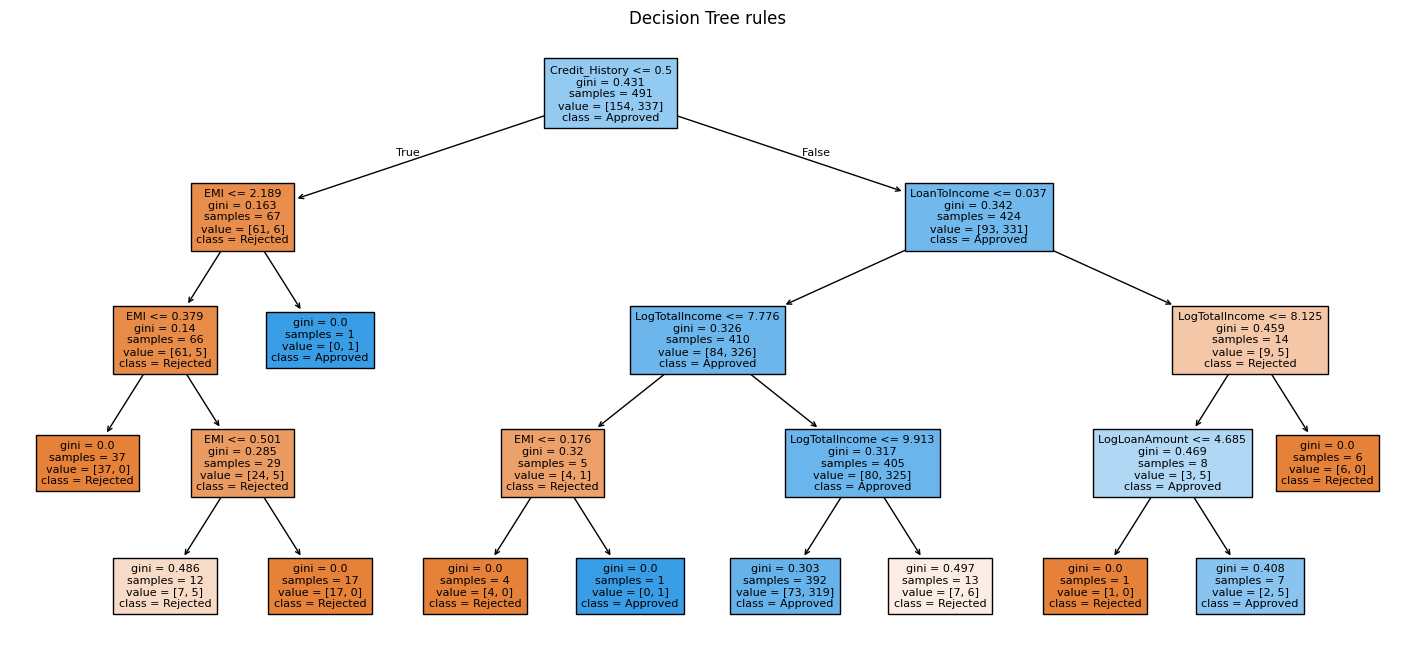

Top 5 Random Forest features:
Credit_History    0.227
LoanToIncome      0.159
LogTotalIncome    0.156
EMI               0.136
LogLoanAmount     0.129
dtype: float64


In [ ]:
from sklearn.tree import plot_tree

feature_names = X.columns
coef = pd.Series(models["LogReg"].coef_[0], index=feature_names).sort_values()
imp = pd.Series(models["RF"].feature_importances_, index=feature_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
coef.plot(kind="barh", ax=axes[0], color=["#4C9F70" if v > 0 else "#D1495B" for v in coef])
axes[0].set_title("Logistic Regression coefficients (green = pushes toward approval)")
imp.plot(kind="barh", ax=axes[1], color="#4C78A8")
axes[1].set_title("Random Forest feature importance")
plt.tight_layout(); plt.show()

plt.figure(figsize=(18, 8))
plot_tree(models["Tree"], feature_names=feature_names, class_names=["Rejected", "Approved"],
          filled=True, fontsize=8)
plt.title("Decision Tree rules"); plt.show()

print("Top 5 Random Forest features:")
print(imp.sort_values(ascending=False).head(5).round(3))


=== Gender ===


,n,Actual approval rate,Selection rate,Recall (TPR),False positive rate
Female,25,0.560,0.560,0.929,0.091
Male,98,0.724,0.765,0.915,0.370


Selection-rate gap: 0.205 | Disparate impact ratio: 0.73 (below 0.80 is a warning sign)

=== Married ===


,n,Actual approval rate,Selection rate,Recall (TPR),False positive rate
No,44,0.568,0.568,0.800,0.263
Yes,79,0.759,0.810,0.967,0.316


Selection-rate gap: 0.242 | Disparate impact ratio: 0.70 (below 0.80 is a warning sign)

=== Property_Area ===


,n,Actual approval rate,Selection rate,Recall (TPR),False positive rate
Rural,34,0.647,0.676,0.773,0.500
Semiurban,49,0.735,0.755,0.972,0.154
Urban,40,0.675,0.725,0.963,0.231


Selection-rate gap: 0.079 | Disparate impact ratio: 0.90 (below 0.80 is a warning sign)


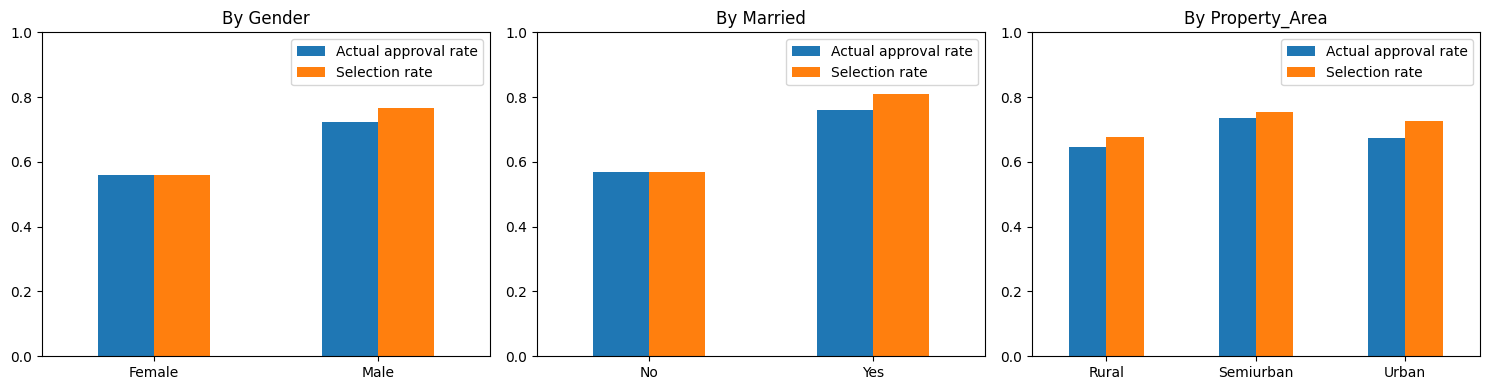

In [ ]:
audit_model = "RF"
pred = models[audit_model].predict(X_test)
sens_test = sensitive.loc[X_test.index]
audit = sens_test.assign(actual=y_test.values, pred=pred)

def group_report(col):
    rows = {}
    for g, df_g in audit.groupby(col):
        a, p = df_g["actual"], df_g["pred"]
        rows[g] = {
            "n": len(df_g),
            "Actual approval rate": a.mean(),
            "Selection rate": p.mean(),
            "Recall (TPR)": ((p == 1) & (a == 1)).sum() / max((a == 1).sum(), 1),
            "False positive rate": ((p == 1) & (a == 0)).sum() / max((a == 0).sum(), 1),
        }
    t = pd.DataFrame(rows).T.round(3)
    t["n"] = t["n"].astype(int)
    hi, lo = t["Selection rate"].max(), t["Selection rate"].min()
    return t, hi - lo, (lo / hi if hi > 0 else np.nan)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Gender", "Married", "Property_Area"]):
    t, gap, ratio = group_report(col)
    print(f"\n=== {col} ===")
    display(t)
    print(f"Selection-rate gap: {gap:.3f} | Disparate impact ratio: {ratio:.2f} (below 0.80 is a warning sign)")
    t[["Actual approval rate", "Selection rate"]].plot(kind="bar", ax=ax)
    ax.set_title(f"By {col}"); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [ ]:
!pip install imbalanced-learn -q
from imblearn.over_sampling import SMOTE

# SMOTE is applied to the training data only, never to the test data
X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Before:", y_train.value_counts().to_dict(), " After:", y_res.value_counts().to_dict())

rf_smote = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_res, y_res)
pred = rf_smote.predict(X_test)
rep = classification_report(y_test, pred, output_dict=True, zero_division=0)

compare = results.loc[["RF", "RF (balanced)"]].copy()
compare.loc["RF + SMOTE"] = [rep["1"]["precision"], rep["1"]["recall"], rep["1"]["f1-score"],
                             rep["0"]["recall"], rep["accuracy"],
                             roc_auc_score(y_test, rf_smote.predict_proba(X_test)[:, 1])]
compare.round(3)

Before: {1: 337, 0: 154}  After: {1: 337, 0: 337}


,Precision,Recall,F1,Recall (rejected),Accuracy,AUC
Model,,,,,,
RF,0.876,0.918,0.897,0.711,0.854,0.854
RF (balanced),0.876,0.918,0.897,0.711,0.854,0.853
RF + SMOTE,0.880,0.859,0.869,0.737,0.821,0.853
